# LLM Lab 

**M2 VMI · Multi-modalité et IA générative**


## 0 — Imports, reproducibility, and output folder

In [1]:
import os, gc, json, time, random
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
    DataCollatorWithPadding, pipeline
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, matthews_corrcoef
)

SEED = 42
MODEL_NAME = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MAX_LENGTH = 128
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
EPOCHS = 3
EARLY_STOP_PATIENCE = 2
CLASS_NAMES = ['negative', 'positive']

RESULTS_DIR = Path('/kaggle/working/llm_results_v2') if Path('/kaggle/working').exists() else Path('llm_results_v2')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / 'checkpoints').mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'not available')
print('torch:', torch.__version__)
print('Output folder:', RESULTS_DIR)
print('Each result will be saved immediately after completion.')

Device: cuda | GPU: Tesla T4
torch: 2.11.0+cu130
Output folder: /kaggle/working/llm_results_v2
Each result will be saved immediately after completion.


## 1 — Load and inspect the dataset

In [2]:
dataset = load_dataset('cornell-movie-review-data/rotten_tomatoes')
print(dataset)
print('First training example:', dataset['train'][0])
print('Label names:', dataset['train'].features['label'].names)

for split in ['train', 'validation', 'test']:
    counts = pd.Series(list(dataset[split]['label'])).value_counts().sort_index()
    print(f'{split}: {len(dataset[split]):,} examples | negative={counts.get(0, 0):,} | positive={counts.get(1, 0):,}')

assert dataset['train'].features['label'].names in (
    ['neg', 'pos'],
    ['negative', 'positive']
), "Unexpected label ordering"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
test_texts = list(dataset['test']['text'])
y_test = np.asarray(list(dataset['test']['label']), dtype=int)
assert len(test_texts) == len(y_test) and all(isinstance(x, str) for x in test_texts)
print('Tokenizer ready. Test data:', len(test_texts))

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

... (6 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Tokenizer ready. Test data: 1066


## 2 — Tokenization and data loaders

This cell builds the loaders used by Parts 2 and 3. It must run after dataset loading in any new Kaggle session.


In [3]:
def tokenize_rows(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH)

tok_data = dataset.map(tokenize_rows, batched=True, desc='Tokenizing movie reviews')
tok_data = tok_data.remove_columns('text').rename_column('label', 'labels')
tok_data.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
collator = DataCollatorWithPadding(tokenizer=tokenizer)

def fresh_train_loader():
    # Same seed in every experiment = repeatable shuffling.
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(tok_data['train'], batch_size=TRAIN_BATCH_SIZE,
                      shuffle=True, collate_fn=collator, generator=gen)

validation_loader = DataLoader(tok_data['validation'], batch_size=EVAL_BATCH_SIZE,
                               shuffle=False, collate_fn=collator)
test_loader = DataLoader(tok_data['test'], batch_size=EVAL_BATCH_SIZE,
                         shuffle=False, collate_fn=collator)
print('Data loaders ready | validation batches:', len(validation_loader),
      '| test batches:', len(test_loader))


Tokenizing movie reviews:   0%|          | 0/8530 [00:00<?, ? examples/s]

Tokenizing movie reviews:   0%|          | 0/1066 [00:00<?, ? examples/s]

Tokenizing movie reviews:   0%|          | 0/1066 [00:00<?, ? examples/s]

Data loaders ready | validation batches: 34 | test batches: 34


## 3 — Evaluation utilities

Every experiment uses **exactly the same test split** and reports: accuracy, balanced accuracy, macro/weighted precision-recall-F1, class-specific scores, confusion matrix and ROC-AUC. Prediction tables contain review text, predictions and confidence so we can analyze mistakes.


In [4]:
def slugify(s):
    return ''.join(c if c.isalnum() else '_' for c in s.lower()).strip('_')


def save_evaluation(name, y_true, probabilities_positive, elapsed_seconds, extra=None):
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(probabilities_positive, dtype=float)
    assert y_true.shape == prob.shape and np.isfinite(prob).all()
    assert ((prob >= 0) & (prob <= 1)).all(), 'Expected scores in [0, 1]'
    pred = (prob >= 0.5).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(
        y_true, pred, labels=[0, 1], average='macro', zero_division=0)
    pr_w, rc_w, f1_w, _ = precision_recall_fscore_support(
        y_true, pred, labels=[0, 1], average='weighted', zero_division=0)
    report = classification_report(y_true, pred, labels=[0, 1],
                                   target_names=CLASS_NAMES, zero_division=0,
                                   output_dict=True)
    roc_auc = float(roc_auc_score(y_true, prob)) if len(np.unique(y_true)) == 2 else float('nan')
    result = {
        'experiment': name,
        'accuracy': float(accuracy_score(y_true, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, pred)),
        'precision_macro': float(pr), 'recall_macro': float(rc), 'f1_macro': float(f1),
        'precision_weighted': float(pr_w), 'recall_weighted': float(rc_w), 'f1_weighted': float(f1_w),
        'roc_auc': roc_auc, 'mcc': float(matthews_corrcoef(y_true, pred)),
        'time_seconds': round(float(elapsed_seconds), 1),
        'test_samples': int(len(y_true))
    }
    if extra:
        result.update(extra)
    slug = slugify(name)

    # Save results after EACH experiment (not only after the final comparison cell).
    with open(RESULTS_DIR / f'{slug}_metrics.json', 'w') as f:
        json.dump(result, f, indent=2)
    pd.DataFrame(report).transpose().to_csv(RESULTS_DIR / f'{slug}_class_report.csv')
    pred_df = pd.DataFrame({
        'review': test_texts, 'true_label': y_true, 'predicted_label': pred,
        'positive_score': prob, 'predicted_class_confidence': np.maximum(prob, 1 - prob),
        'correct': (pred == y_true)
    })
    pred_df.to_csv(RESULTS_DIR / f'{slug}_predictions.csv', index=False)

    print('\n' + '=' * 72)
    print(name)
    print(classification_report(y_true, pred, target_names=CLASS_NAMES, zero_division=0))
    print(f'Accuracy: {result["accuracy"]:.4f} | Macro F1: {result["f1_macro"]:.4f} '
          f'| ROC-AUC: {roc_auc:.4f} | Time: {elapsed_seconds:.1f}s')

    fig, ax = plt.subplots(figsize=(4.7, 4.0))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred, labels=[0, 1]),
                           display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name + ' — confusion matrix')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{slug}_confusion.png', dpi=150)
    plt.show()

    if np.isfinite(roc_auc):
        fpr, tpr, _ = roc_curve(y_true, prob)
        fig, ax = plt.subplots(figsize=(4.7, 4.0))
        ax.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
        ax.plot([0, 1], [0, 1], '--', alpha=0.5, label='Random baseline')
        ax.set(xlabel='False positive rate', ylabel='True positive rate', title=name + ' — ROC')
        ax.legend(loc='lower right')
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / f'{slug}_roc.png', dpi=150)
        plt.show()
    print('Saved metrics, classification report, predictions, confusion matrix and ROC plot.')
    return result


def load_saved_results():
    rows = []
    for file in sorted(RESULTS_DIR.glob('*_metrics.json')):
        with open(file) as f:
            rows.append(json.load(f))
    if not rows:
        print('No saved results yet. Run at least one experiment first.')
        return pd.DataFrame()
    df = pd.DataFrame(rows).drop_duplicates('experiment', keep='last')
    order = ['Part 1 - Zero-shot', 'Part 2 - Strict linear probe',
             'Part 3A - Full fine-tuning', 'Part 3B - Last 4 layers',
             'Optional - Head-only fine-tuning', 'Optional - Last 8 layers']
    df['__order'] = df['experiment'].map({s: i for i, s in enumerate(order)}).fillna(999)
    return df.sort_values('__order').drop(columns='__order').reset_index(drop=True)

print('Evaluation and incremental saving ready.')

Evaluation and incremental saving ready.


## Part 1 — Inference without training (required)

PART 1 — PRETRAINED INFERENCE


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Example: [{'label': 'positive', 'score': 0.9847092628479004}, {'label': 'neutral', 'score': 0.01182967983186245}, {'label': 'negative', 'score': 0.003461067797616124}]

Part 1 - Zero-shot
              precision    recall  f1-score   support

    negative       0.76      0.88      0.81       533
    positive       0.86      0.72      0.78       533

    accuracy                           0.80      1066
   macro avg       0.81      0.80      0.80      1066
weighted avg       0.81      0.80      0.80      1066

Accuracy: 0.8002 | Macro F1: 0.7989 | ROC-AUC: 0.8760 | Time: 12.4s


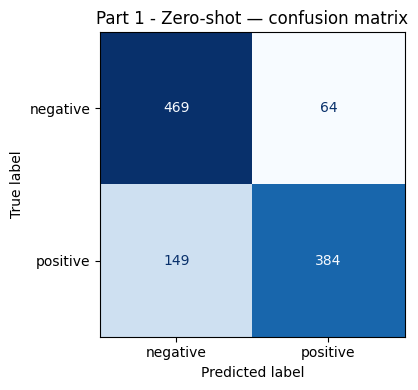

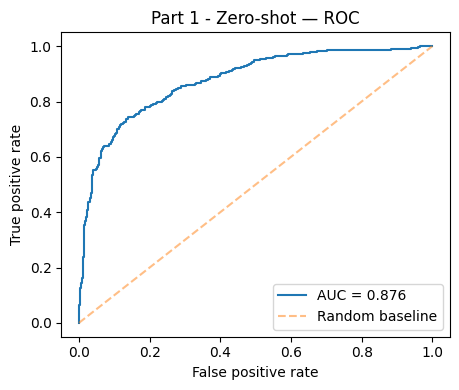

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
Neutral was the highest 3-class score for 280/1066 reviews.


In [5]:
print('PART 1 — PRETRAINED INFERENCE')
t0 = time.perf_counter()
classifier = pipeline('text-classification', model=MODEL_NAME, tokenizer=tokenizer,
                      device=0 if DEVICE.type == 'cuda' else -1)
print('Example:', classifier('I love this movie!', top_k=None))

raw_scores = classifier(test_texts, batch_size=EVAL_BATCH_SIZE, top_k=None,
                        truncation=True, max_length=MAX_LENGTH)
assert len(raw_scores) == len(y_test)
binary_scores = []
neutral_first = 0
for all_labels in raw_scores:
    scores = {str(item['label']).lower(): float(item['score']) for item in all_labels}
    assert 'negative' in scores and 'positive' in scores and 'neutral' in scores, scores
    if max(scores, key=scores.get) == 'neutral':
        neutral_first += 1
    negative, positive = scores['negative'], scores['positive']
    binary_scores.append(positive / (positive + negative + 1e-12))

save_evaluation('Part 1 - Zero-shot', y_test, binary_scores,
                time.perf_counter() - t0,
                extra={'neutral_was_top_label': int(neutral_first),
                       'trainable_parameters': 0,
                       'method': 'pretrained 3-way sentiment scores converted to binary'})
print(f'Neutral was the highest 3-class score for {neutral_first}/{len(test_texts)} reviews.')

### Part 1 — Token IDs and contextual embeddings for “I love this movie!”

In [6]:
prompt = 'I love this movie!'
inputs = tokenizer(prompt, return_tensors='pt').to(DEVICE)
# Reuse the backbone from the pipeline, avoiding another 500 MB model download.
encoder = classifier.model.roberta
encoder.eval()
with torch.inference_mode():
    embeddings = encoder(**inputs).last_hidden_state[0].float().cpu().numpy()
ids = inputs['input_ids'][0].cpu().tolist()
token_table = pd.DataFrame({
    'token': tokenizer.convert_ids_to_tokens(ids),
    'id': ids,
    'embedding_dimensions': [embeddings.shape[-1]] * len(ids),
    'first_8_values': [np.round(e[:8], 4).tolist() for e in embeddings]
})
display(token_table)
token_table.to_csv(RESULTS_DIR / 'tokens_and_embeddings_preview.csv', index=False)
np.save(RESULTS_DIR / 'tokens_and_embeddings_full.npy', embeddings)
print('Full embeddings shape:', embeddings.shape)
# Free the inference model before training to avoid GPU memory problems.
del encoder, classifier, inputs, embeddings, raw_scores
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

,token,id,embedding_dimensions,first_8_values
0,<s>,0,768,"[-0.05700000002980232, 0.6744999885559082, -0...."
1,I,100,768,"[-0.0869000032544136, 0.2590000033378601, -0.2..."
2,Ġlove,657,768,"[-0.34279999136924744, 0.48899999260902405, 0...."
3,Ġthis,42,768,"[-0.18060000240802765, 0.20329999923706055, 0...."
4,Ġmovie,1569,768,"[-0.3546999990940094, 0.29170000553131104, 0.1..."
5,!,328,768,"[-0.11800000071525574, 0.16300000250339508, 0...."
6,</s>,2,768,"[-0.05700000002980232, 0.6744999885559082, -0...."


Full embeddings shape: (7, 768)


## Training setup for Parts 2 and 3

- **Strict linear probing:** freeze the entire encoder and train **one `nn.Linear(768, 2)`**. The representation is the first (CLS / `<s>`) contextual token.
- **Full fine-tuning:** train the RoBERTa backbone and its new two-class head.
- **Partial fine-tuning:** train only the final 4 transformer blocks and the classification head. The first 8 encoder blocks and embeddings remain frozen.
- **Optional head-only:** replicate the previous notebook's RoBERTa head-only approach, which is **not strictly linear**, because RoBERTa's built-in head contains a nonlinear hidden layer.
- **Optional last-8:** unfreeze the last 8 transformer blocks to explore the parameter/performance trade-off.

All training experiments use the **train** split, checkpoint selection by **validation macro-F1**, and a final evaluation on the **test** split. The model can be stopped early after no improvement for 2 epochs. Each completed experiment writes its own JSON, CSV, and figures.

In [7]:
class StrictLinearProbe(nn.Module):
    """Frozen RoBERTa backbone + a genuinely single linear output layer."""
    def __init__(self, pretrained_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(pretrained_name)
        self.encoder.requires_grad_(False)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask, labels=None):
        self.encoder.eval()  # no dropout in frozen features
        with torch.no_grad():
            cls_features = self.encoder(input_ids=input_ids,
                                        attention_mask=attention_mask).last_hidden_state[:, 0, :]
        logits = self.classifier(cls_features)
        loss = F.cross_entropy(logits, labels) if labels is not None else None
        return SimpleNamespace(loss=loss, logits=logits)


def create_model(mode):
    if mode == 'strict_linear':
        model = StrictLinearProbe(MODEL_NAME)
    else:
        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True,
            id2label={0: 'negative', 1: 'positive'},
            label2id={'negative': 0, 'positive': 1}
        )
        if mode in ('head_only', 'last_4', 'last_8'):
            model.roberta.requires_grad_(False)
            if mode in ('last_4', 'last_8'):
                count = 4 if mode == 'last_4' else 8
                for layer in model.roberta.encoder.layer[-count:]:
                    layer.requires_grad_(True)
        elif mode != 'full':
            raise ValueError('Unknown experiment mode: ' + mode)
    model = model.to(DEVICE)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f'{mode}: {trainable:,} / {total:,} trainable parameters ({100*trainable/total:.2f}%)')
    return model, trainable, total


def set_training_modes(model, mode):
    model.train()
    if mode == 'strict_linear':
        model.encoder.eval()
    elif mode == 'head_only':
        model.roberta.eval()
    elif mode in ('last_4', 'last_8'):
        # Keep frozen layers deterministic (avoid dropout changes in frozen features).
        model.roberta.embeddings.eval()
        n_frozen = 12 - (4 if mode == 'last_4' else 8)
        for layer in model.roberta.encoder.layer[:n_frozen]:
            layer.eval()

print('Model configurations are ready.')

Model configurations are ready.


In [8]:
def evaluate_model(model, data_loader):
    model.eval()
    y_true, probabilities = [], []
    loss_sum, count = 0.0, 0
    with torch.inference_mode():
        for batch in data_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast('cuda', enabled=DEVICE.type == 'cuda'):
                output = model(**batch)
            p_positive = torch.softmax(output.logits.float(), dim=-1)[:, 1]
            y_true.extend(batch['labels'].cpu().tolist())
            probabilities.extend(p_positive.cpu().tolist())
            batch_size = len(batch['labels'])
            loss_sum += output.loss.item() * batch_size
            count += batch_size
    return np.asarray(y_true, dtype=int), np.asarray(probabilities, dtype=float), loss_sum / count

print('Prediction and validation function ready.')

Prediction and validation function ready.


In [9]:
def train_experiment(name, mode, learning_rate, epochs=EPOCHS):
    print('\n' + '=' * 75)
    print('STARTING:', name, '| mode:', mode, '| epochs:', epochs)
    print('=' * 75, flush=True)
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    torch.manual_seed(SEED)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)

    total_start = time.perf_counter()
    model, n_trainable, n_total = create_model(mode)
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                  lr=learning_rate, weight_decay=0.01)
    amp_enabled = DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    train_loader = fresh_train_loader()
    best_validation_f1 = -1.0
    best_epoch = 0
    stagnant_epochs = 0
    history = []
    ckpt = RESULTS_DIR / 'checkpoints' / f'{slugify(name)}_best.pt'
    training_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        set_training_modes(model, mode)
        epoch_total_loss, seen = 0.0, 0
        progress = tqdm(train_loader, desc=f'{mode}: epoch {epoch}/{epochs}', unit='batch', leave=True)
        for batch in progress:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', enabled=amp_enabled):
                output = model(**batch)
                loss = output.loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), 1.0)
            scaler.step(optimizer)
            scaler.update()
            batch_size = len(batch['labels'])
            epoch_total_loss += float(loss.detach()) * batch_size
            seen += batch_size
            progress.set_postfix(loss=f'{epoch_total_loss / seen:.4f}')

        val_true, val_prob, val_loss = evaluate_model(model, validation_loader)
        val_pred = (val_prob >= 0.5).astype(int)
        val_acc = float(accuracy_score(val_true, val_pred))
        val_f1 = float(precision_recall_fscore_support(
            val_true, val_pred, average='macro', zero_division=0)[2])
        epoch_row = {'experiment': name, 'epoch': epoch,
                     'train_loss': epoch_total_loss / seen, 'val_loss': float(val_loss),
                     'val_accuracy': val_acc, 'val_f1_macro': val_f1}
        history.append(epoch_row)
        pd.DataFrame(history).to_csv(RESULTS_DIR / f'{slugify(name)}_history.csv', index=False)
        print(f'Epoch {epoch}/{epochs}: train loss={epoch_row["train_loss"]:.4f}, '
              f'val loss={val_loss:.4f}, val accuracy={val_acc:.4f}, '
              f'val macro F1={val_f1:.4f}', flush=True)
        if val_f1 > best_validation_f1 + 1e-8:
            best_validation_f1 = val_f1
            best_epoch = epoch
            stagnant_epochs = 0
            torch.save(model.state_dict(), ckpt)
            print('Saved better checkpoint:', ckpt, flush=True)
        else:
            stagnant_epochs += 1
            if stagnant_epochs >= EARLY_STOP_PATIENCE:
                print('Early stopping: validation macro F1 did not improve.', flush=True)
                break

    train_seconds = time.perf_counter() - training_start
    print(f'Loading best checkpoint from epoch {best_epoch} and testing...', flush=True)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    test_true, test_probability, test_loss = evaluate_model(model, test_loader)
    peak_mem_mb = round(torch.cuda.max_memory_allocated() / (1024**2), 1) if amp_enabled else None
    result = save_evaluation(name, test_true, test_probability,
                             time.perf_counter() - total_start,
                             extra={'mode': mode, 'learning_rate': learning_rate,
                                    'epochs_completed': len(history), 'best_epoch': best_epoch,
                                    'best_validation_f1': best_validation_f1,
                                    'train_loss_best_epoch': history[best_epoch - 1]['train_loss'],
                                    'test_loss': float(test_loss),
                                    'trainable_parameters': int(n_trainable),
                                    'total_parameters': int(n_total),
                                    'trainable_percent': round(100 * n_trainable / n_total, 3),
                                    'training_seconds': round(train_seconds, 1),
                                    'peak_cuda_memory_mb': peak_mem_mb})
    print('COMPLETED:', name, '| saved checkpoint and metrics.', flush=True)
    del model, optimizer, scaler
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result

print('Training loop ready. The next three experiment cells start training.')

Training loop ready. The next three experiment cells start training.


## Part 2 — Strict linear probing (**required**)

Only one `nn.Linear(768, 2)` layer learns. All RoBERTa encoder parameters are frozen. Compare it with the no-training baseline.


STARTING: Part 2 - Strict linear probe | mode: strict_linear | epochs: 3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                        | Status     |  | 
---------------------------+------------+--+-
classifier.dense.bias      | UNEXPECTED |  | 
classifier.out_proj.weight | UNEXPECTED |  | 
classifier.out_proj.bias   | UNEXPECTED |  | 
classifier.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


strict_linear: 1,538 / 124,647,170 trainable parameters (0.00%)


strict_linear: epoch 1/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 1/3: train loss=0.3948, val loss=0.3460, val accuracy=0.8508, val macro F1=0.8506
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/part_2___strict_linear_probe_best.pt


strict_linear: epoch 2/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 2/3: train loss=0.3621, val loss=0.3555, val accuracy=0.8462, val macro F1=0.8461


strict_linear: epoch 3/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 3/3: train loss=0.3552, val loss=0.3774, val accuracy=0.8349, val macro F1=0.8331
Early stopping: validation macro F1 did not improve.
Loading best checkpoint from epoch 1 and testing...

Part 2 - Strict linear probe
              precision    recall  f1-score   support

    negative       0.80      0.88      0.84       533
    positive       0.87      0.78      0.82       533

    accuracy                           0.83      1066
   macro avg       0.83      0.83      0.83      1066
weighted avg       0.83      0.83      0.83      1066

Accuracy: 0.8311 | Macro F1: 0.8307 | ROC-AUC: 0.9096 | Time: 41.2s


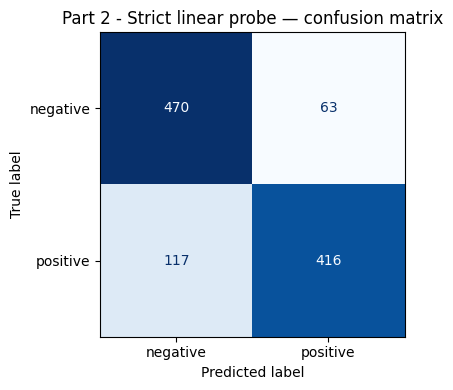

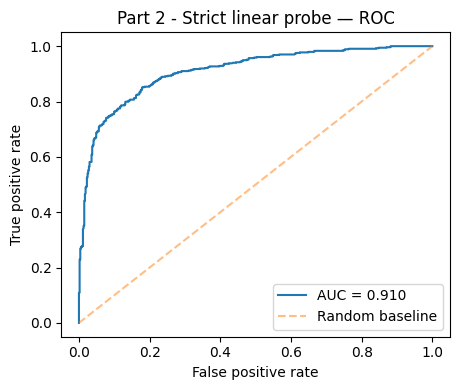

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
COMPLETED: Part 2 - Strict linear probe | saved checkpoint and metrics.


In [10]:
strict_result = train_experiment('Part 2 - Strict linear probe', 'strict_linear', learning_rate=1e-3)

## Part 3A — Full fine-tuning (**required**)


STARTING: Part 3A - Full fine-tuning | mode: full | epochs: 3


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect 

full: 124,647,170 / 124,647,170 trainable parameters (100.00%)


full: epoch 1/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 1/3: train loss=0.3605, val loss=0.2785, val accuracy=0.8865, val macro F1=0.8865
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/part_3a___full_fine_tuning_best.pt


full: epoch 2/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 2/3: train loss=0.2288, val loss=0.3565, val accuracy=0.8865, val macro F1=0.8863


full: epoch 3/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 3/3: train loss=0.1659, val loss=0.4763, val accuracy=0.8837, val macro F1=0.8837
Early stopping: validation macro F1 did not improve.
Loading best checkpoint from epoch 1 and testing...

Part 3A - Full fine-tuning
              precision    recall  f1-score   support

    negative       0.87      0.87      0.87       533
    positive       0.87      0.87      0.87       533

    accuracy                           0.87      1066
   macro avg       0.87      0.87      0.87      1066
weighted avg       0.87      0.87      0.87      1066

Accuracy: 0.8687 | Macro F1: 0.8687 | ROC-AUC: 0.9421 | Time: 163.6s


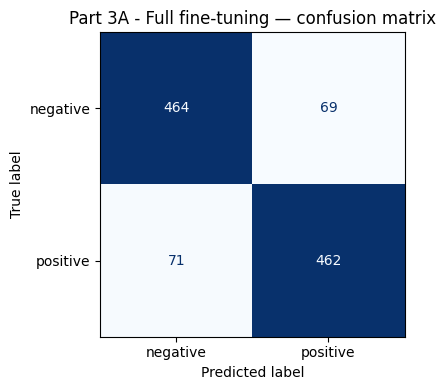

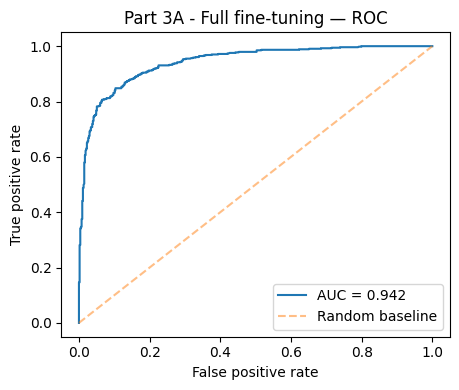

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
COMPLETED: Part 3A - Full fine-tuning | saved checkpoint and metrics.


In [11]:
full_result = train_experiment('Part 3A - Full fine-tuning', 'full', learning_rate=2e-5)

## Part 3B — Freeze encoder layers and fine-tune the last 4 (**required**)


STARTING: Part 3B - Last 4 layers | mode: last_4 | epochs: 3


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect 

last_4: 28,943,618 / 124,647,170 trainable parameters (23.22%)


last_4: epoch 1/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 1/3: train loss=0.3687, val loss=0.2952, val accuracy=0.8771, val macro F1=0.8771
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/part_3b___last_4_layers_best.pt


last_4: epoch 2/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 2/3: train loss=0.2844, val loss=0.3256, val accuracy=0.8799, val macro F1=0.8799
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/part_3b___last_4_layers_best.pt


last_4: epoch 3/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 3/3: train loss=0.2226, val loss=0.3965, val accuracy=0.8565, val macro F1=0.8557
Loading best checkpoint from epoch 2 and testing...

Part 3B - Last 4 layers
              precision    recall  f1-score   support

    negative       0.84      0.90      0.87       533
    positive       0.89      0.83      0.86       533

    accuracy                           0.86      1066
   macro avg       0.86      0.86      0.86      1066
weighted avg       0.86      0.86      0.86      1066

Accuracy: 0.8630 | Macro F1: 0.8629 | ROC-AUC: 0.9401 | Time: 70.6s


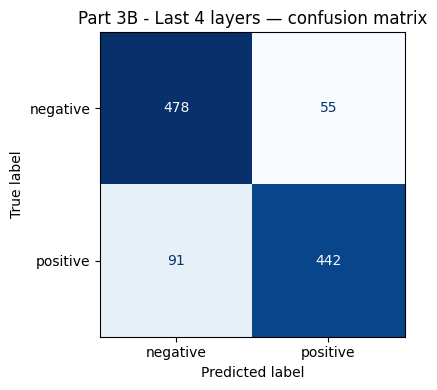

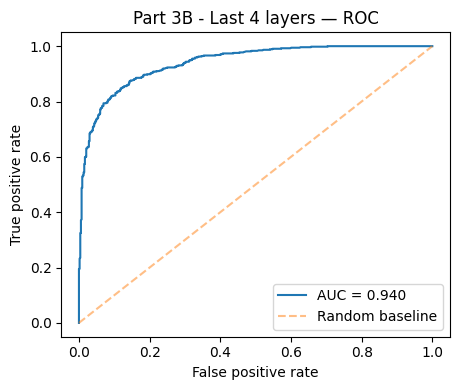

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
COMPLETED: Part 3B - Last 4 layers | saved checkpoint and metrics.


In [12]:
partial_result = train_experiment('Part 3B - Last 4 layers', 'last_4', learning_rate=5e-5)

## Checkpoint — Compare all completed experiments (safe to run **now**, even if you skip bonuses)

Saved metrics for 4 completed experiments:


,experiment,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc,trainable_percent,time_seconds
0,Part 1 - Zero-shot,0.8002,0.8080,0.8002,0.7989,0.7989,0.8760,NaN,12.4
1,Part 2 - Strict linear probe,0.8311,0.8346,0.8311,0.8307,0.8307,0.9096,0.001,41.2
2,Part 3A - Full fine-tuning,0.8687,0.8687,0.8687,0.8687,0.8687,0.9421,100.000,163.6
3,Part 3B - Last 4 layers,0.8630,0.8647,0.8630,0.8629,0.8629,0.9401,23.220,70.6


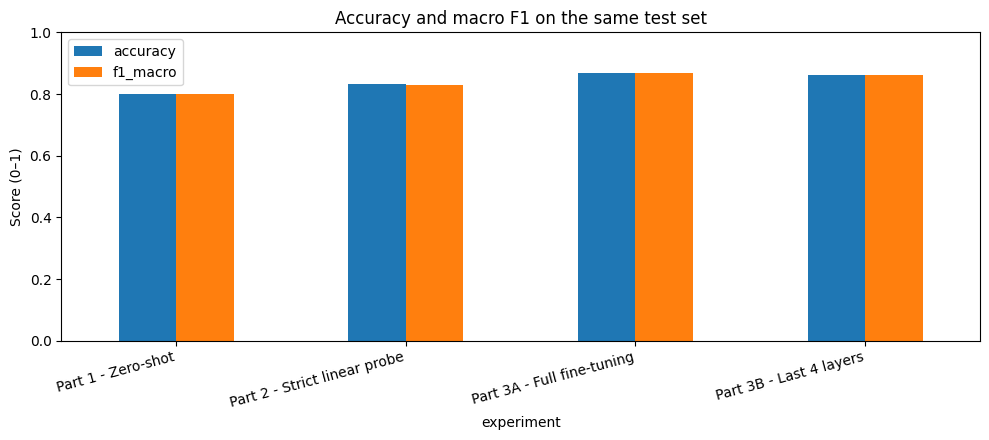

In [13]:
summary = load_saved_results()
if not summary.empty:
    columns = ['experiment', 'accuracy', 'precision_macro', 'recall_macro',
               'f1_macro', 'f1_weighted', 'roc_auc', 'trainable_percent', 'time_seconds']
    print('Saved metrics for', len(summary), 'completed experiments:')
    display(summary.reindex(columns=columns).round(4))
    summary.to_csv(RESULTS_DIR / 'comparison_all_available.csv', index=False)
    ax = summary.set_index('experiment')[['accuracy', 'f1_macro']].plot.bar(figsize=(10, 4.5), rot=15)
    ax.set_ylabel('Score (0–1)')
    ax.set_ylim(0, 1)
    ax.set_title('Accuracy and macro F1 on the same test set')
    plt.xticks(ha='right')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'comparison_available.png', dpi=150)
    plt.show()

## Error analysis — Understand what the models get wrong

This section does not train anything. It reads saved test predictions, displays confident errors and uncertain reviews.

In [14]:
summary = load_saved_results()
if not summary.empty:
    # Use the completed experiment with the highest macro F1 (descriptive only).
    chosen_name = summary.sort_values('f1_macro', ascending=False).iloc[0]['experiment']
    pred_file = RESULTS_DIR / f'{slugify(chosen_name)}_predictions.csv'
    errors = pd.read_csv(pred_file)
    print('Analyzing:', chosen_name)
    print('Errors:', int((~errors['correct']).sum()), 'out of', len(errors))
    print('\n10 most confident mistakes:')
    display(errors.loc[~errors['correct']].sort_values('predicted_class_confidence', ascending=False)
            [['review', 'true_label', 'predicted_label', 'positive_score']].head(10))
    print('\n10 most uncertain predictions (closest to a 50/50 decision):')
    errors['distance_to_half'] = (errors['positive_score'] - 0.5).abs()
    display(errors.sort_values('distance_to_half')
            [['review', 'true_label', 'predicted_label', 'positive_score', 'correct']].head(10))
    errors.loc[~errors['correct']].to_csv(RESULTS_DIR / 'highest_f1_model_errors.csv', index=False)

Analyzing: Part 3A - Full fine-tuning
Errors: 140 out of 1066

10 most confident mistakes:


,review,true_label,predicted_label,positive_score
607,though its rather routine script is loaded wit...,0,1,0.992947
611,one regards reign of fire with awe . what a va...,0,1,0.990750
922,mariah carey gives us another peek at some of ...,0,1,0.989150
633,an encouraging effort from mccrudden,0,1,0.988992
989,the film has too many spots where it's on slip...,0,1,0.988458
664,what [frei] gives us . . . is a man who uses t...,0,1,0.985635
870,the stunt work is top-notch ; the dialogue and...,0,1,0.981595
725,"never again , while nothing special , is pleas...",0,1,0.980129
949,"a very familiar tale , one that's been told by...",0,1,0.970964
632,"according to wendigo , 'nature' loves the memb...",0,1,0.965479



10 most uncertain predictions (closest to a 50/50 decision):


,review,true_label,predicted_label,positive_score,correct
481,an older cad instructs a younger lad in zen an...,1,0,0.499104,False
782,"this is very much of a mixed bag , with enough...",0,0,0.496040,True
81,zhuangzhuang creates delicate balance of style...,1,1,0.504188,True
544,a film without surprise geared toward maximum ...,0,0,0.494734,True
411,you won't look at religious fanatics -- or bac...,1,1,0.507223,True
41,waiting for godard can be fruitful : 'in prais...,1,0,0.490476,False
698,while this one gets off with a good natured wa...,0,0,0.487614,True
225,it's unlikely we'll see a better thriller this...,1,1,0.513594,True
167,whether our action-and-popcorn obsessed cultur...,1,0,0.483690,False
1025,though there are many tense scenes in trapped ...,0,0,0.481517,True


## Optional experiment A — Original RoBERTa classification head (not strictly linear)

This reproduces the previous notebook's head-only setup more closely: the encoder is frozen, but the default RoBERTa head contains a nonlinear dense layer.


STARTING: Optional - Head-only fine-tuning | mode: head_only | epochs: 3


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect 

head_only: 592,130 / 124,647,170 trainable parameters (0.48%)


head_only: epoch 1/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 1/3: train loss=0.4311, val loss=0.3543, val accuracy=0.8490, val macro F1=0.8490
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/optional___head_only_fine_tuning_best.pt


head_only: epoch 2/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 2/3: train loss=0.4000, val loss=0.4123, val accuracy=0.8330, val macro F1=0.8311


head_only: epoch 3/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 3/3: train loss=0.4062, val loss=0.5118, val accuracy=0.7833, val macro F1=0.7763
Early stopping: validation macro F1 did not improve.
Loading best checkpoint from epoch 1 and testing...

Optional - Head-only fine-tuning
              precision    recall  f1-score   support

    negative       0.82      0.85      0.83       533
    positive       0.84      0.81      0.83       533

    accuracy                           0.83      1066
   macro avg       0.83      0.83      0.83      1066
weighted avg       0.83      0.83      0.83      1066

Accuracy: 0.8302 | Macro F1: 0.8302 | ROC-AUC: 0.9115 | Time: 39.3s


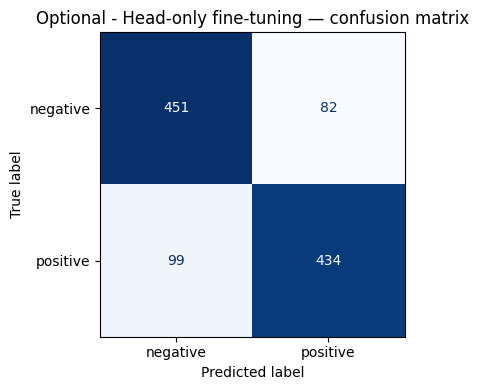

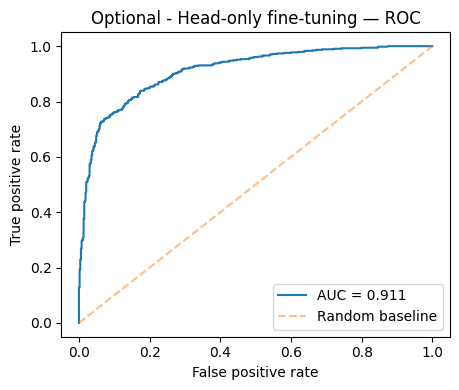

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
COMPLETED: Optional - Head-only fine-tuning | saved checkpoint and metrics.


In [15]:
head_result = train_experiment('Optional - Head-only fine-tuning', 'head_only', learning_rate=1e-3)

## Optional experiment B — Fine-tune the last 8 encoder layers

Compare unfreezing **8 layers** versus **4 layers**. The full model is still used for inference, so this mainly changes the number of trainable parameters and the training computation.


STARTING: Optional - Last 8 layers | mode: last_8 | epochs: 3


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect 

last_8: 57,295,106 / 124,647,170 trainable parameters (45.97%)


last_8: epoch 1/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 1/3: train loss=0.3597, val loss=0.3065, val accuracy=0.8752, val macro F1=0.8752
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/optional___last_8_layers_best.pt


last_8: epoch 2/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 2/3: train loss=0.2319, val loss=0.3726, val accuracy=0.8827, val macro F1=0.8824
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/optional___last_8_layers_best.pt


last_8: epoch 3/3:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 3/3: train loss=0.1506, val loss=0.4725, val accuracy=0.8837, val macro F1=0.8834
Saved better checkpoint: /kaggle/working/llm_results_v2/checkpoints/optional___last_8_layers_best.pt
Loading best checkpoint from epoch 3 and testing...

Optional - Last 8 layers
              precision    recall  f1-score   support

    negative       0.82      0.94      0.88       533
    positive       0.93      0.79      0.86       533

    accuracy                           0.87      1066
   macro avg       0.88      0.87      0.87      1066
weighted avg       0.88      0.87      0.87      1066

Accuracy: 0.8668 | Macro F1: 0.8660 | ROC-AUC: 0.9397 | Time: 103.9s


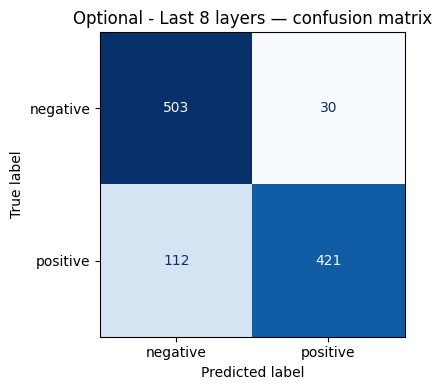

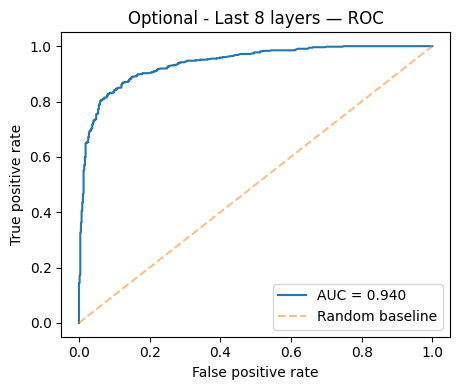

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
COMPLETED: Optional - Last 8 layers | saved checkpoint and metrics.


In [16]:
last8_result = train_experiment('Optional - Last 8 layers', 'last_8', learning_rate=3e-5)

## Final analysis and plots 

,experiment,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc,mcc,trainable_parameters,trainable_percent,training_seconds,time_seconds,best_epoch
0,Part 1 - Zero-shot,0.8002,0.8002,0.8080,0.8002,0.7989,0.7989,0.8760,0.6082,0,NaN,NaN,12.4,NaN
1,Part 2 - Strict linear probe,0.8311,0.8311,0.8346,0.8311,0.8307,0.8307,0.9096,0.6657,1538,0.001,38.5,41.2,1.0
2,Part 3A - Full fine-tuning,0.8687,0.8687,0.8687,0.8687,0.8687,0.8687,0.9421,0.7373,124647170,100.000,161.9,163.6,1.0
3,Part 3B - Last 4 layers,0.8630,0.8630,0.8647,0.8630,0.8629,0.8629,0.9401,0.7277,28943618,23.220,68.9,70.6,2.0
4,Optional - Head-only fine-tuning,0.8302,0.8302,0.8305,0.8302,0.8302,0.8302,0.9115,0.6607,592130,0.475,37.6,39.3,1.0
5,Optional - Last 8 layers,0.8668,0.8668,0.8757,0.8668,0.8660,0.8660,0.9397,0.7424,57295106,45.966,102.2,103.9,3.0


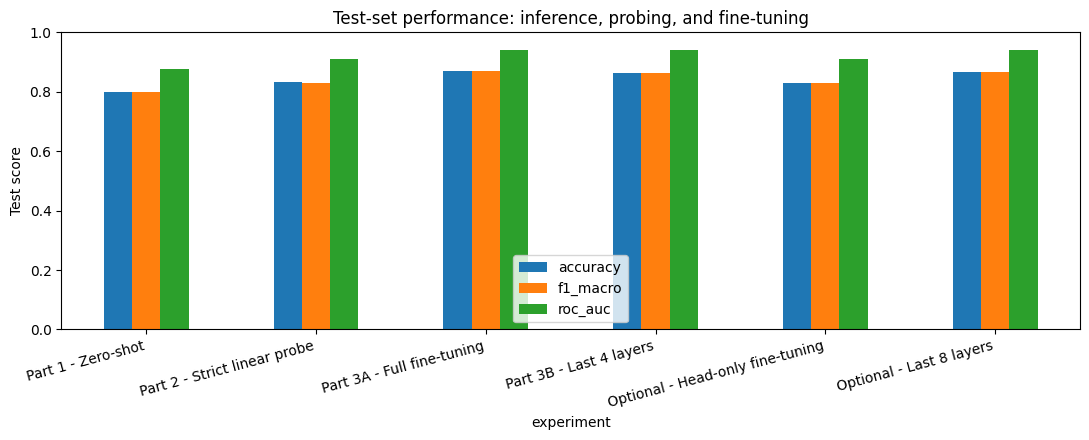

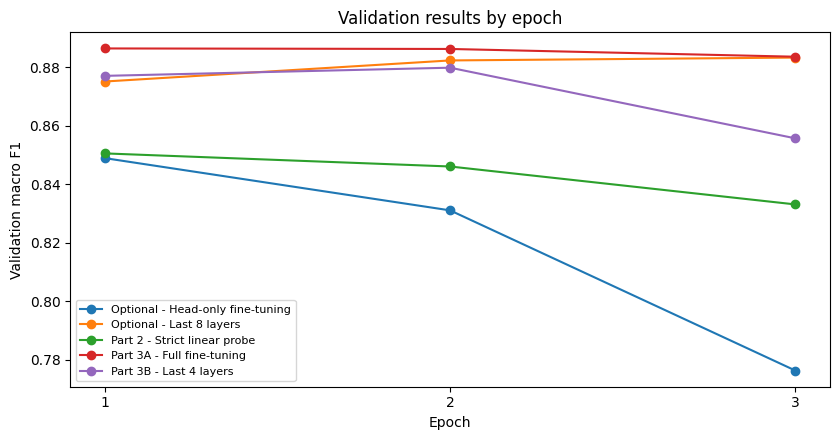

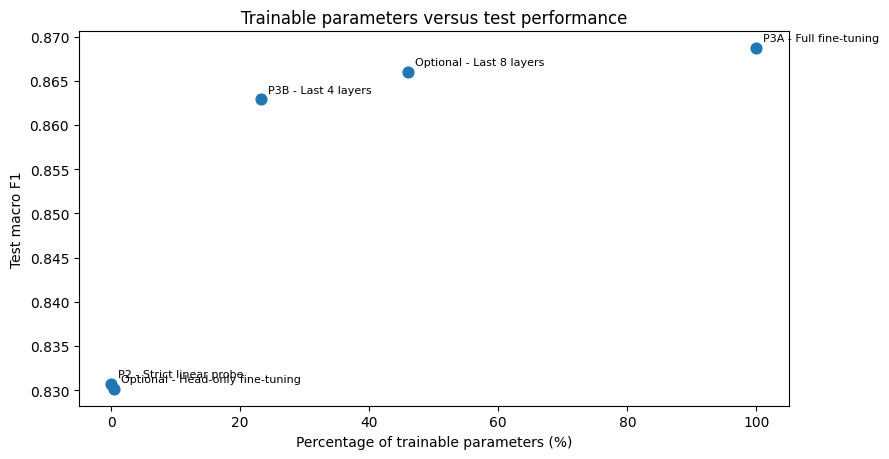

Done. Every available result is saved in: /kaggle/working/llm_results_v2
Do not delete your original completed notebook; this is an extra set of experiments.


In [17]:
summary = load_saved_results()
if not summary.empty:
    display_columns = ['experiment', 'accuracy', 'balanced_accuracy', 'precision_macro',
                       'recall_macro', 'f1_macro', 'f1_weighted', 'roc_auc', 'mcc',
                       'trainable_parameters', 'trainable_percent',
                       'training_seconds', 'time_seconds', 'best_epoch']
    display(summary.reindex(columns=display_columns).round(4))
    summary.to_csv(RESULTS_DIR / 'comparison_metrics_final.csv', index=False)

    fig, ax = plt.subplots(figsize=(11, 4.5))
    summary.set_index('experiment')[['accuracy', 'f1_macro', 'roc_auc']].plot.bar(ax=ax, rot=15)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Test score')
    ax.set_title('Test-set performance: inference, probing, and fine-tuning')
    plt.xticks(ha='right')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / 'final_metrics_comparison.png', dpi=150)
    plt.show()

    history_files = sorted(RESULTS_DIR.glob('*_history.csv'))
    if history_files:
        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        for history_file in history_files:
            hist = pd.read_csv(history_file)
            ax.plot(hist['epoch'], hist['val_f1_macro'], marker='o', label=hist['experiment'].iloc[0])
        ax.set(xlabel='Epoch', ylabel='Validation macro F1', title='Validation results by epoch')
        ax.set_xticks(range(1, EPOCHS + 1))
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / 'validation_f1_history.png', dpi=150)
        plt.show()

    tuned = summary[summary['trainable_parameters'].notna()].copy()
    tuned = tuned[tuned['trainable_parameters'] > 0]
    if not tuned.empty:
        fig, ax = plt.subplots(figsize=(9, 4.7))
        ax.scatter(tuned['trainable_percent'], tuned['f1_macro'], s=60)
        for _, row in tuned.iterrows():
            ax.annotate(row['experiment'].replace('Part ', 'P'),
                        (row['trainable_percent'], row['f1_macro']),
                        xytext=(5, 5), textcoords='offset points', fontsize=8)
        ax.set(xlabel='Percentage of trainable parameters (%)', ylabel='Test macro F1',
               title='Trainable parameters versus test performance')
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / 'trainable_parameters_vs_f1.png', dpi=150)
        plt.show()

    print('Done. Every available result is saved in:', RESULTS_DIR)
    print('Do not delete your original completed notebook; this is an extra set of experiments.')